<img src="images/strathsdr_banner.png" align="left" >

# RFSoC-PYNQ Multi-Tile Synchronisation with Digital Feature Sync - Demonstrator.
---

<div class="alert alert-box alert-info">
Please use Jupyter Labs http://&lt;board_ip_address&gt;/lab for this notebook.
</div>

This notebook demonstrates the use of the Multi-Tile Synchronisation (MTS) engine to synchronise the RF-DACs and RF-ADCs when Numerically Controlled Oscillators (NCOs) have been used to mix a signal up to a carrier frequency.
<p align="center">
  <img src="images/zcu208_image.jpeg" width="40%" />
</p>

## Table of Contents
* [Muti-tile Synchronisation](#mts-overview)
* [System Overview](#system-overview)
    * [Hardware](#hardware-overview)
    * [Software](#software-overview)
* [System Setup](#system-setup)
    * [Hardware](#hardware-setup)
    * [Software](#software-setup)
* [MTS Demonstration](#mts-demo)
    * [Waveform Generation](#waveform-gen)
    * [No Synchronisation - ADC Capture](#no-synch-capture)
    * [FIFO Synchronisation - ADC Capture](#fifo-synch-capture)
    * [Digital Feature Synchronisation - ADC Capture](#digital-feature-synch-capture)


## References

[1]&nbsp;<a id="ref-1"></a> [AMD Xilinx, "Zynq UltraScale+ RFSoC RF Data Converter v2.6 Gen 1/2/3/DFE LogiCORE IP Product Guide (PG269)"](https://docs.amd.com/r/en-US/pg269-rf-data-converter/Multi-Tile-Synchronization)

[2]&nbsp;<a id="ref-2"></a> [AMD Xilinx, "RFSOC-PYNQ Multi-Tile Synchronization Overlay Example"](https://github.com/Xilinx/RFSoC-MTS)

[3]&nbsp;<a id="ref-3"></a> [AMD Xilinx, "Synchronization of Signal Processing in Multiple RF Data Converter Subsystems (XAPP1349)"](https://docs.amd.com/r/en-US/xapp1349-rfdc-subsystems)

----

## Multi-tile Synchronisation <a class="anchor" id="mts-overview"></a>
RFSoC devices can achieve synchronisation across their integrated Radio Frequency Data Converter (RFDC) tiles via the MTS engine, which provides a simplified equivalent of the JESD204B SYSREF-based synchronisation scheme. The MTS engine incorporates a SYSREF timing signal that acts as a common timing reference across clock domains. This is necessary because the RFSoC’s hardened Radio Frequency Analogue-to-Digital Converters (RF-ADCs) and Digital-to-Analogue Converters (RF-DACs) operate at different clock rates to the Programmable Logic (PL).

To enable data transfer between the PL and RFDC clock domains, each RF-ADC and RF-DAC block includes a dedicated gearbox FIFO. While all blocks within a single tile are intrinsically synchronised, different tiles exhibit non-deterministic latency across power cycles. The SYSREF signal is captured in both clock domains (referred to as PL and ANALOG) and passed through the FIFOs. A state machine measures the latency introduced by the FIFOs, allowing the tiles to be latency-aligned and achieve synchronisation across the RFDC tiles. Analog SYSREF capture within the RFDC must be enabled throughout this FIFO synchronisation process, after which it can be disabled via the RFDC driver. See [[1]](#ref-1) and [[3]](#ref-3).

When digital feature synchronisation is required - for example, when Numerically Controlled Oscillators (NCOs) are enabled within RFDC blocks - the SYSREF signal can be reused to synchronously reset phase and update frequencies of all the RF-DACs and/or RF-ADCs at the same time. To expose this behaviour, the relevant RFDC blocks should be configured with their event sources set to ```xrfdc.EVNT_SRC_SYSREF```. Doing so allows changes to the RFDC block configuration, such as phase reset and frequency updates, to be armed and applied to all RFDC blocks synchronously on the rising edge of the ANALOG SYSREF signal. This can be achieved by briefly re-enabling SYSREF capture for a duration greater than one SYSREF period, ensuring that a rising edge is captured.

Therefore, to achieve reliable synchronisation across RFDC tiles, the following aspects must be aligned:

1. Gearbox FIFO synchronisation.
2. NCO phase and frequency synchronisation.

The remainder of this notebook describes the combined hardware and software approaches used to achieve and demonstrate MTS with digital feature synchronisation on RFSoC.

----

## System Overview <a class="anchor" id="system-overview"></a>
This section provides technical overview of both the hardware and software design used to demonstrate MTS.

### Hardware <a class="anchor" id="hardware-overview"></a>

To demonstrate the stages of MTS, an overlay was implemented in the PL to support (1) RFDC tile synchronisation, (2) signal generation for transmission across all RF-DACs, and (3) capture of signals from all RF-ADCs. An overview of the MTS demonstrator system is shown in [Figure 1](#fig-1).

<a class="anchor" id="fig-1"></a>
<figure>
    <img src="images/zcu208_overlay.png" height='70%' width="70%" />
    <figcaption><b>Figure 1: MTS Demonstrator System Overview.</b></figcaption>
</figure>

The demonstrator consists of three hierarchies; Signal Capture, Signal Player, and Clock Tree.
* The Signal Player hierarchy contains the ```bram_player```, Block Memory Generator, and BRAM Controller IP cores. The Block Memory Generator and BRAM Controller enable signals generated in the Processing System (PS) to be written to memory accessible within the Programmable Logic (PL). The ```bram_player``` core iterates over each sample in this memory buffer when a GPIO enable signal is asserted, outputting a continuously repeating signal. The generated signal is then duplicated and sent to the RFSoC's Radio Frequency Digital-to-Analogue Converters (RF-DACs) via an AXI-Stream Broadcaster.
* The Signal Capture hierarchy is very similar to the Signal Player. It includes an instance of the ```bram_capture```, Block Memory Generator and BRAM Controller IP cores for each Radio Frequency Analogue-to-Digital Converter (RF-ADC) in the RFSoC. All ```bram_capture``` cores are triggered by a common GPIO signal, ensuring that samples from the RF-ADCs are written to their respective memory buffers simultaneously. The BRAM Controller enables these synchronously captured signals to be accessed from the PS for visualisation.
* The Clock Tree hierarchy consists of a Clock Wizard and Flip-Flop (FF) cores to enable reliable capture of the PL SYSREF signal within the PL clock domain. Details on SYSREF capture in the PL can be found in [[1]](#ref-1). The documentation indicates the use of a Clock Wizard for cases where the ADCs and DACs operate on different clocks. In this design, both ADCs and DACs operate on the same clock; however, the Clock Wizard is still used to reset the output clock after the external clocks have been configured. This was found to be necessary to achieve reliable synchronisation of the ADCs across runs.

The system uses the same LMK04828 and LMX2594 clock configurations as [[2]](#ref-2). The fabric clock and PL-SYSREF, acquired directly from the LMK04828, operates at 500 MHz and 5 MHz, respectively. All RFDCs sample at 4 GSps, with 8x Digital Up Conversion (DUC) and Digital Down Conversion (DDC) chains, and NCOs enabled.


### Software <a class="anchor" id="software-overview"></a>

To complement the hardware design in [Figure 1](#fig-1), a set of Python drivers were developed and modified to demonstrate MTS. Custom ```SignalPlayer``` and ```SignalCapture``` drivers were created to interface with the corresponding PL hierarchies, enabling DAC waveform generation and synchronous ADC data capture, respectively. These drivers were designed to be board agnostic and can support any number of ADCs signal captures.

Modifications were made to PYNQ's ```xrfdc``` Python wrapper to expose the required functionality from ```xrfdc_functions.c```, allowing the MTS engine to be utlised with digital feature synchronisation.

A seperate ```MultiTileSynchronisation``` driver was developed to directly interface with the PYNQ RFDC driver, as well as the Clock Wizard core, seen in [Figure 1](#fig-1), which must be software reset prior to synchronisation. This driver accepts a reference tile and bitmasks for the RF-ADCs and RF-DACs, and exposes the functionality required to synchronise FIFOs and reset or update NCO frequencies. Notably, these operations can be performed after initialisation of the driver.

Finally, the ```Overlay``` driver provides high-level access to the design, including all IP cores and drivers described in [System Overview](#system-overview), and is responsible for system configuration and interfacing with hardware.

----

## System Setup <a class="anchor" id="system-setup"></a>
This section explains the steps required to setup the hardware and software for the MTS demonstrator notebook.

### Hardware <a class="anchor" id="hardware-setup"></a>

This demonstration supports synchronisation across all **8 RF-ADC** and **8 RF-DAC channels** on the board, which requires the use of **four Carlisle cables**.

However, it is recognised that the standard ZCU208 kit only includes two Carlisle cables. The demonstration will still run with two cables, but you should keep in mind that only 2 RF-ADC and 2 RF-DAC tiles will be demonstrated at a time in this case.

The setup instructions describe how to configure the system for both cases (2-cable and 4-cable configurations). See the [setup instructions](00_rfsoc_mts_setup.ipynb) for more details.


<div class="alert alert-box alert-danger">
<b>Caution:</b>
    In this demonstration, we generate tones using the RFSoC development board. Your device should be setup in loopback mode. You should understand that the RFSoC platform can also transmit RF signals wirelessly. Remember that unlicensed wireless transmission of RF signals may be illegal in your geographical location. Radio signals may also interfere with nearby devices, such as pacemakers and emergency radio equipment. Note that it is also illegal to intercept and decode particular RF signals. If you are unsure, please seek professional support.
</div>

### Software <a class="anchor" id="software-setup"></a>

The only libraries required for this demonstration are `numpy` and `rfsoc_mts`.

* The `rfsoc_mts` library provides the hardware design (`.xsa` file) and all associated drivers described in [Software Overview](#software-overview), including the `Overlay` driver, which provides top-level access to the design.
* The `numpy` library is used to generate custom waveforms for transmission via the RF-DAC.


##### Driver Access and Modification

For convenience, a copy of the drivers used in this demonstration is also included in the local `./modules/` directory. This allows a user to:

* Access and inspect the source code  
* Understand the driver implementation  
* Modify the drivers to suit custom design requirements  

If you wish to make changes, modify the drivers in ```./modules/``` and update the import in the first line of the code cell below to:

```from modules.overlay import Overlay```

##### Overlay Configuration

The `Overlay` class accepts several parameters, including:

* LMK04828 and LMX2594 clock frequencies  
* ADC and DAC reference tiles  
* A binary bitmask specifying which tiles are synchronised by the MTS engine  

Exposing these parameters allows you to partially adapt the Vivado MTS design for your own applications and validate your bitstream within this notebook. This will require you to specify a new ```.xsa``` file for the ```bitfile_name``` argument.

The `Overlay` class also supports automatic configuration of the MTS engine during initialisation by setting ```sync_on_init=True```. In this notebook, however, ```sync_on_init=False``` is used to allow each step of the tile synchronisation process to be executed manually. A notebook demonstrating MTS configuration during initialisation is available [here](02_rfsoc_mts.ipynb).

The following code cell is required to setup the environment.

In [1]:
from rfsoc_mts.overlay import Overlay
import numpy as np

ol = Overlay(bitfile_name=None, # Default bitstream
             lmx_freq=500,
             lmk_freq=500,
             dac_mts_reftile=2,
             adc_mts_reftile=2,
             dac_mts_tiles=0b1111,
             adc_mts_tiles=0b1111,
             sync_on_init=False)

----

## MTS Demonstration <a class="anchor" id="mts-demo"></a>

### Waveform Generation <a class="anchor" id="waveform-gen"></a>
The following cell is used to characterise and select a waveform from ```{'Sinusoid', 'Chirp'}```. Signals are generated to occupy the entire width of the buffer length. The initial NCO frequencies of the RFDCs are also set here.

In [2]:
# -- Characterise waveform --
Fs = 500.0e6                         # Baseband sampling rate produced by signal generator - determined by the hardware design.
N = int(ol.signal_player.length/2)   # Signal Player buffer length

DAC_Amplitude = 2**14-1              # Scaling by the fractional bits
Fc = 1000                            # NCO frequency

offset = 12.5                        # NCO offset for sinusoid case - frequency of downconverted signal observed
chirp_range = [-80e6, 80e6]          # Chirp frequency range

sig_type = 'Sinusoid'

# -- Generate waveform --
if sig_type == 'Sinusoid':
    signal = DAC_Amplitude * (1+1j*0)*np.ones(N)
    ol.configure_rfdcs(dac_freq = Fc, adc_freq = Fc-offset) # Apply ADC frequency offset so sinusoid can be observed after DDC
    
elif sig_type == 'Chirp':
    t = np.arange(N, dtype=np.single) / Fs
    window = np.hanning(N)
    
    k = (chirp_range[1] - chirp_range[0]) / t[-1]
    phase = 2*np.pi*(chirp_range[0]*t + 0.5*k*(t**2))
    signal = DAC_Amplitude * (window * np.exp(1j*phase)).astype(np.complex64)
    
    ol.configure_rfdcs(dac_freq = Fc, adc_freq = Fc)
    
else:
    raise ValueError(f"Unsupported signal type: {sig_type}")

The generated signal is then loaded into Signal Player's memory buffer, and the GPIO enable is asserted to begin transmitting the signal out of both the RF-DACs.

In [3]:
# -- Ensure disabled signal output --
ol.signal_player.disable()

# -- Load signal and re-enable output --
ol.signal_player.load_signal(signal)
ol.signal_player.enable()

---

### No Synchronisation - ADC Capture <a class="anchor" id="no-synch-capture"></a>

At this stage, no MTS has been carried out and it is very unlikely that the signals are synchronised. The code cell below briefly triggers the GPIO in the Signal Capture hierarchy, which is connected to each of the ```signal_capture``` cores. This causes samples received from each ADC to be written synchronously to their respective memories in the PL. Each ADCs memory buffer is then read from the PS and both the real and imaginary components are plotted via ```ol.plot_adc()```. It should be observed that there is no synchronisation between the captured signals.

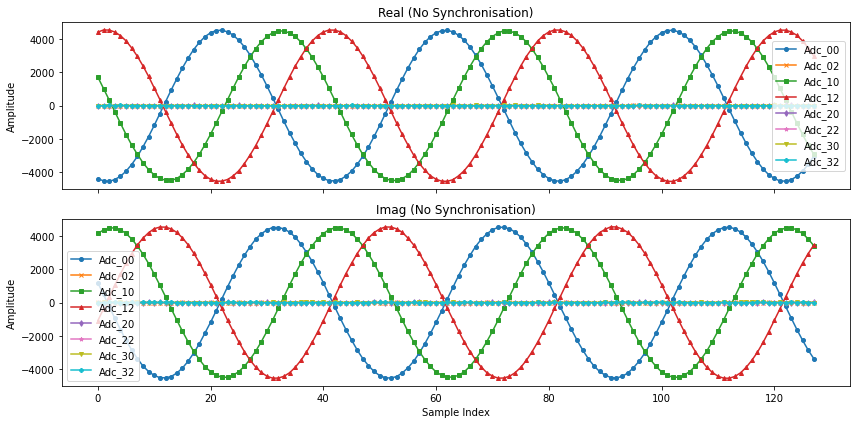

In [4]:
ol.plot_adc(
    sample_matrix=ol.signal_capture.capture_adc() ,
    window=128,
    title="No Synchronisation"
)

---

### Gearbox FIFO Synchronisation - ADC Capture <a class="anchor" id="fifo-synch-capture"></a>
Upon initialisation of the ```Overlay``` class, the attribute ```ol.mts``` was created; an instance of ```MultiTileSynchronisation```. This exposes the the method ```_sync_fifos()``` to synchronise the gearbox FIFOs of all the MTS selected RF-DAC and RF-ADC tiles. This function is called below.

In [5]:
ol.mts._sync_fifos()

The subsequent signals sampled by the ADC are re-captured by the Signal Capture hierarchy and plotted below.

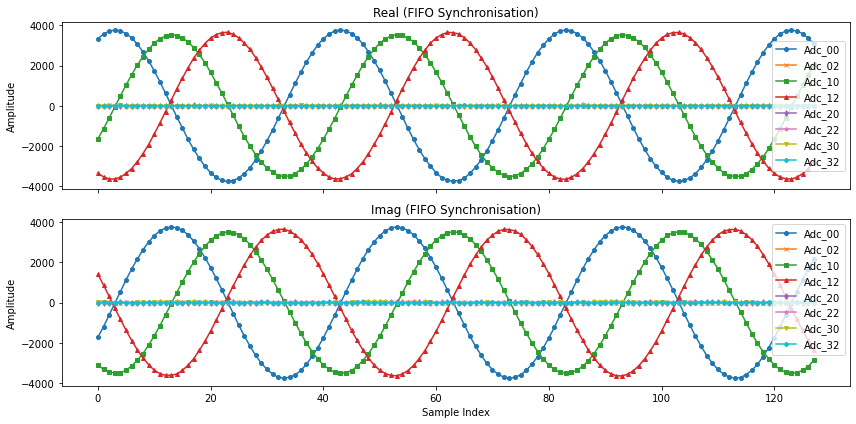

In [6]:
ol.plot_adc(
    sample_matrix=ol.signal_capture.capture_adc(),
    window=128,
    title="FIFO Synchronisation"
)

The signal above should still demonstrate that signals are not yet synchronised. However, from the driver we can request a report of the RFDC latencies by calling ```report_latency()```. The configured MTS DACs and ADCs should share the same gearbox FIFO "Latency" field as a result of this stage.

In [7]:
ol.mts.report_latency()

--- DAC Tile 0 report ---
  Latency:	224
  Offset:	0
  DTC Code:	85
  Num Windows:	4
  Max Gap:	42
  Min Gap:	12
  Max Overlap:	0

--- DAC Tile 1 report ---
  Latency:	224
  Offset:	0
  DTC Code:	88
  Num Windows:	4
  Max Gap:	42
  Min Gap:	12
  Max Overlap:	1

--- DAC Tile 2 report ---
  Latency:	224
  Offset:	0
  DTC Code:	86
  Num Windows:	4
  Max Gap:	42
  Min Gap:	13
  Max Overlap:	1

--- DAC Tile 3 report ---
  Latency:	224
  Offset:	0
  DTC Code:	87
  Num Windows:	4
  Max Gap:	42
  Min Gap:	13
  Max Overlap:	1

--- ADC Tile 0 report ---
  Latency:	96
  Offset:	0
  DTC Code:	76
  Num Windows:	3
  Max Gap:	42
  Min Gap:	25
  Max Overlap:	1

--- ADC Tile 1 report ---
  Latency:	96
  Offset:	0
  DTC Code:	78
  Num Windows:	4
  Max Gap:	42
  Min Gap:	5
  Max Overlap:	1

--- ADC Tile 2 report ---
  Latency:	96
  Offset:	0
  DTC Code:	79
  Num Windows:	4
  Max Gap:	41
  Min Gap:	5
  Max Overlap:	1

--- ADC Tile 3 report ---
  Latency:	96
  Offset:	0
  DTC Code:	79
  Num Windows:	4
  Ma

### Digital Feature Synchronisation - ADC Capture <a class="anchor" id="digital-feature-synch-capture"></a>

The final step is to synchronise the NCOs of each RF-DAC and RF-ADC block on the rising edge of the ANALOG SYSREF signal. The ```_sync_nco_dac()``` and ```_sync_nco_adc()``` functions configure the relevant blocks to use ```xrfdc.EVNT_SRC_SYSREF```, arm NCO frequency updates and phase resets, and then briefly enable and disable SYSREF capture to trigger synchronous application of these changes.

The following cell calls these functions with the desired frequency parameters.

In [8]:
Fc = 1000
offset = 12.5

ol.mts._sync_nco_dac(Fc)
ol.mts._sync_nco_adc(Fc-offset)

The cell below should demonstrate synchronisation across the connected tiles.

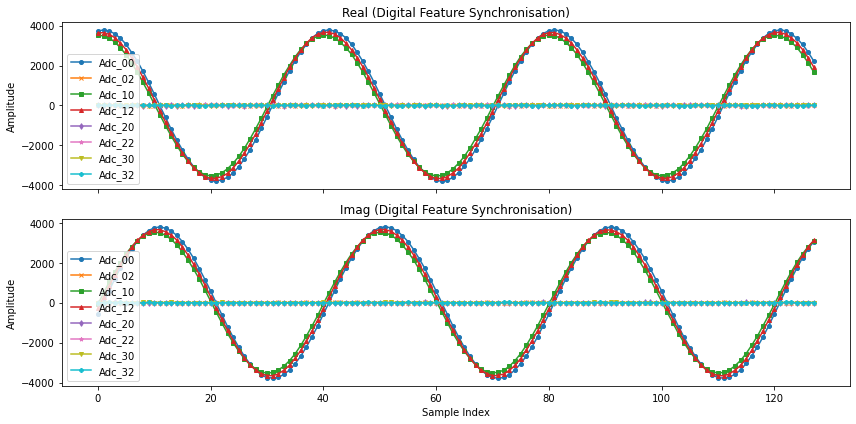

In [9]:
ol.plot_adc(
    sample_matrix=ol.signal_capture.capture_adc(),
    window=128,
    title="Digital Feature Synchronisation"
)